# Embedding validation

**One question:** Do the relationships learned by the TGNN correspond to actual similarities
in wallet trading behavior?

**Method, and why it's built this way:**
- We already learned (in `tgnn.ipynb`) that picking the *top-K most similar pairs* and eyeballing
  them is easily fooled by artifacts (crowd timestamps, degree-1 wallets converging by accident).
  So this notebook samples pairs **at random**, at scale, and looks at the correlation across
  the whole distribution — not just the extreme tail.
- We control for the **activity/degree confound** that has shown up at every stage of this
  project (feature clustering, static GraphSAGE, TGNN PCA collapse) — high-degree wallets can
  look "similar" for trivial reasons.
- We compare against a **null baseline** (shuffled embeddings). If the real correlation isn't
  clearly separated from the null, the answer is "no, not convincingly."

In [4]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
rng = np.random.default_rng(SEED)

## 1. Load embeddings and wallet features — independently, from disk

In [5]:
wallet_embeddings = pd.read_parquet("../data/processed/wallet_embeddings.parquet")
wallet_features = pd.read_parquet("../data/processed/wallet_features.parquet")
temporal_edges = pd.read_parquet("../data/processed/temporal_edges.parquet")

print("Wallet embeddings:", wallet_embeddings.shape)
print("Wallet features:", wallet_features.shape)
print("Temporal edges (raw, pre-dedup):", temporal_edges.shape)

Wallet embeddings: (2356, 35)
Wallet features: (2356, 15)
Temporal edges (raw, pre-dedup): (103779, 17)


In [6]:
emb_cols = [c for c in wallet_embeddings.columns if c.startswith("emb_")]
embedding_matrix = wallet_embeddings[emb_cols].values
print("Embedding matrix:", embedding_matrix.shape)

connected_mask = ~wallet_embeddings["is_isolated"].values
print(f"Connected wallets: {connected_mask.sum()} / {len(wallet_embeddings)}")

# Merge features onto the same wallet ordering as the embeddings — do NOT assume row order matches
merged = wallet_embeddings[["proxyWallet", "train_degree", "is_isolated"]].merge(
    wallet_features, on="proxyWallet", how="left"
)
assert (merged["proxyWallet"] == wallet_embeddings["proxyWallet"]).all(), "row order mismatch — fix merge before continuing"
print("Missing wallet_features rows:", merged["trade_count"].isna().sum())

Embedding matrix: (2356, 32)
Connected wallets: 2140 / 2356
Missing wallet_features rows: 0


## 2. Deduplicate the crowd-timestamp artifact

Same fix as `tgnn_v2.ipynb` — a wallet pair sharing a busy timestamp should count once,
not once per pair of split trade fragments.

In [7]:
temporal_edges = temporal_edges.copy()
temporal_edges["pair_key"] = temporal_edges.apply(
    lambda r: tuple(sorted((r["source"], r["target"]))), axis=1
)

temporal_edges_dedup = (
    temporal_edges
    .sort_values("time_diff")
    .drop_duplicates(subset=["pair_key", "timestamp"], keep="first")
    .drop(columns="pair_key")
    .reset_index(drop=True)
)

print(f"Before dedup: {len(temporal_edges)}  After dedup: {len(temporal_edges_dedup)}")

Before dedup: 103779  After dedup: 51356


## 3. Define behavioral similarity — raw feature space, independent of the graph

This is deliberately built from ONLY the static wallet-level features (no graph/edge
information at all), so it's a genuinely independent measure to compare the embeddings against.

In [8]:
behavior_feature_cols = [
    "trade_count", "avg_trade_size", "median_trade_size",
    "avg_price", "buy_ratio", "sell_ratio",
    "price_std", "active_duration_hours"
]

behavior_raw = merged[behavior_feature_cols].fillna(0).copy()

# log-transform the heavy-tailed columns, same treatment as baseline_clustering.ipynb
for col in ["trade_count", "avg_trade_size", "median_trade_size", "active_duration_hours"]:
    behavior_raw[col] = np.log1p(behavior_raw[col])

behavior_matrix = StandardScaler().fit_transform(behavior_raw)
print("Behavior feature matrix:", behavior_matrix.shape)

Behavior feature matrix: (2356, 8)


## 4. Random pair sampling — NOT top-K

Sampling broadly across the whole population avoids the exact failure mode from `tgnn.ipynb`:
extreme-tail pairs turned out to be dominated by artifacts, not real structure. Restricted to
connected wallets, since isolated wallets' embeddings are just a linear function of their own
features by construction — comparing them to behavioral similarity would be circular.

In [9]:
connected_indices = np.where(connected_mask)[0]
print(f"Sampling from {len(connected_indices)} connected wallets")

N_PAIRS = 20000
idx_a = rng.choice(connected_indices, size=N_PAIRS)
idx_b = rng.choice(connected_indices, size=N_PAIRS)

# drop self-pairs
keep = idx_a != idx_b
idx_a, idx_b = idx_a[keep], idx_b[keep]
print(f"{len(idx_a)} random pairs after dropping self-pairs")

Sampling from 2140 connected wallets
19991 random pairs after dropping self-pairs


In [10]:
def row_cosine(matrix, i, j):
    a, b = matrix[i], matrix[j]
    denom = (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))
    denom = np.where(denom == 0, 1e-8, denom)
    return (a * b).sum(axis=1) / denom

embedding_sim = row_cosine(embedding_matrix, idx_a, idx_b)
behavior_sim = row_cosine(behavior_matrix, idx_a, idx_b)

pair_df = pd.DataFrame({
    "idx_a": idx_a, "idx_b": idx_b,
    "embedding_similarity": embedding_sim,
    "behavior_similarity": behavior_sim,
    "degree_a": wallet_embeddings["train_degree"].values[idx_a],
    "degree_b": wallet_embeddings["train_degree"].values[idx_b],
})
pair_df["degree_sum"] = pair_df["degree_a"] + pair_df["degree_b"]
pair_df.head()

,idx_a,idx_b,embedding_similarity,behavior_similarity,degree_a,degree_b,degree_sum
0,207,78,0.977319,-0.259312,3,4,7
1,1834,1709,0.415916,-0.402615,1,9,10
2,1555,506,0.839270,0.994611,2,14,16
3,1046,1689,0.963735,-0.592875,3,47,50
4,1031,1344,0.644566,-0.058215,1,42,43


## 5. The core result — correlation across the random sample

In [11]:
rho, p_value = spearmanr(pair_df["embedding_similarity"], pair_df["behavior_similarity"])
print(f"Spearman correlation (embedding sim vs. behavior sim): rho={rho:.4f}, p={p_value:.2e}")

Spearman correlation (embedding sim vs. behavior sim): rho=0.1068, p=9.10e-52


## 6. Null baseline — shuffle embeddings, recompute

If the real rho isn't clearly outside this null distribution, the correlation above isn't
trustworthy evidence of anything.

In [12]:
N_PERMUTATIONS = 20
null_rhos = []

for _ in range(N_PERMUTATIONS):
    shuffled_order = rng.permutation(len(embedding_matrix))
    shuffled_embedding_matrix = embedding_matrix[shuffled_order]
    sim_null = row_cosine(shuffled_embedding_matrix, idx_a, idx_b)
    rho_null, _ = spearmanr(sim_null, pair_df["behavior_similarity"])
    null_rhos.append(rho_null)

null_rhos = np.array(null_rhos)
print(f"Null rho — mean: {null_rhos.mean():.4f}, std: {null_rhos.std():.4f}, "
      f"range: [{null_rhos.min():.4f}, {null_rhos.max():.4f}]")
print(f"Real rho: {rho:.4f}")
print(f"Real rho is {(rho - null_rhos.mean()) / null_rhos.std():.1f} null-std-devs above the null mean")

Null rho — mean: -0.0019, std: 0.0084, range: [-0.0283, 0.0096]
Real rho: 0.1068
Real rho is 12.9 null-std-devs above the null mean


## 7. Control for the degree/activity confound

Degree has been a confound at every stage of this project. Check whether the correlation
survives once pairs are stratified by how active both wallets are.

In [13]:
pair_df["degree_bucket"] = pd.qcut(pair_df["degree_sum"], q=4, duplicates="drop")

stratified = (
    pair_df
    .groupby("degree_bucket")
    .apply(lambda g: pd.Series({
        "n_pairs": len(g),
        "rho": spearmanr(g["embedding_similarity"], g["behavior_similarity"])[0]
    }))
)
stratified

,n_pairs,rho
degree_bucket,,
"(1.999, 9.0]",5500.0,0.258702
"(9.0, 22.0]",4656.0,0.128104
"(22.0, 89.0]",4846.0,0.056791
"(89.0, 15543.0]",4989.0,0.171273


## 8. Direct validation against the model's own training signal

Separate from raw-feature similarity: for wallet pairs that **actually interacted**
(post-dedup), does the rate of behaviorally-matched events (same_side & same_outcome)
correlate with embedding similarity? This checks whether the model learned to encode
the exact signal it was trained on.

In [14]:
temporal_edges_dedup["behavior_match"] = (
    temporal_edges_dedup["same_side"] & temporal_edges_dedup["same_outcome"]
).astype(int)

wallet_to_idx = dict(zip(wallet_embeddings["proxyWallet"], wallet_embeddings.index))

pair_stats = (
    temporal_edges_dedup
    .assign(pair_key=lambda d: d.apply(lambda r: tuple(sorted((r["source"], r["target"]))), axis=1))
    .groupby("pair_key")
    .agg(n_events=("behavior_match", "size"), match_rate=("behavior_match", "mean"))
    .reset_index()
)

# require a minimum number of events so match_rate isn't noise from a single observation
pair_stats = pair_stats[pair_stats["n_events"] >= 3].copy()
print(f"{len(pair_stats)} wallet pairs with >= 3 real interaction events")

pair_stats["idx_a"] = pair_stats["pair_key"].apply(lambda p: wallet_to_idx.get(p[0]))
pair_stats["idx_b"] = pair_stats["pair_key"].apply(lambda p: wallet_to_idx.get(p[1]))
pair_stats = pair_stats.dropna(subset=["idx_a", "idx_b"])
pair_stats["idx_a"] = pair_stats["idx_a"].astype(int)
pair_stats["idx_b"] = pair_stats["idx_b"].astype(int)

pair_stats["embedding_similarity"] = row_cosine(
    embedding_matrix, pair_stats["idx_a"].values, pair_stats["idx_b"].values
)

rho_direct, p_direct = spearmanr(pair_stats["match_rate"], pair_stats["embedding_similarity"])
print(f"Spearman correlation (behavior_match_rate vs. embedding similarity): "
      f"rho={rho_direct:.4f}, p={p_direct:.2e}, n={len(pair_stats)}")

3963 wallet pairs with >= 3 real interaction events
Spearman correlation (behavior_match_rate vs. embedding similarity): rho=0.1032, p=7.37e-11, n=3963


## 9. Visualize — binned means smooth out the noise in a raw scatter

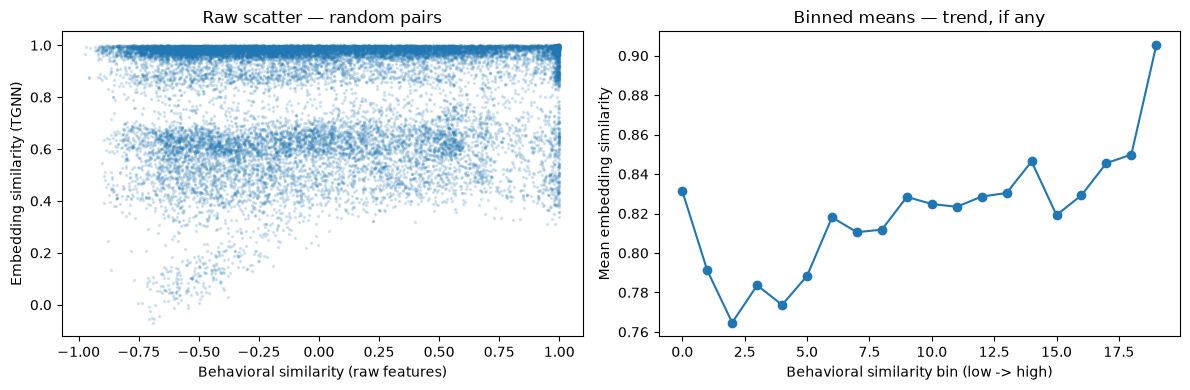

In [15]:
import matplotlib.pyplot as plt

pair_df["behavior_bin"] = pd.qcut(pair_df["behavior_similarity"], q=20, duplicates="drop")
binned = pair_df.groupby("behavior_bin")["embedding_similarity"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(pair_df["behavior_similarity"], pair_df["embedding_similarity"], s=2, alpha=0.15)
axes[0].set_xlabel("Behavioral similarity (raw features)")
axes[0].set_ylabel("Embedding similarity (TGNN)")
axes[0].set_title("Raw scatter — random pairs")

axes[1].plot(range(len(binned)), binned.values, marker="o")
axes[1].set_xlabel("Behavioral similarity bin (low -> high)")
axes[1].set_ylabel("Mean embedding similarity")
axes[1].set_title("Binned means — trend, if any")

plt.tight_layout()
plt.show()

## 10. Verdict

In [16]:
print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(f"Random-pair correlation (feature similarity):  rho={rho:.4f}")
print(f"Null baseline:                                  mean={null_rhos.mean():.4f}, std={null_rhos.std():.4f}")
print(f"Separation from null:                           {(rho - null_rhos.mean()) / null_rhos.std():.1f} std devs")
print(f"Direct validation (actual interaction pairs):   rho={rho_direct:.4f}, n={len(pair_stats)}")
print()
print("Degree-stratified correlation (does it survive controlling for activity?):")
print(stratified)
print()
print("Interpretation guide:")
print("- rho well above null AND consistent across degree buckets -> genuine signal, not an activity artifact")
print("- rho collapses in the degree-stratified view -> still substantially degree-driven")
print("- direct-validation rho much stronger than raw-feature rho -> model learned interaction")
print("  patterns beyond what static features alone would predict (the actual point of using a TGNN)")

SUMMARY
Random-pair correlation (feature similarity):  rho=0.1068
Null baseline:                                  mean=-0.0019, std=0.0084
Separation from null:                           12.9 std devs
Direct validation (actual interaction pairs):   rho=0.1032, n=3963

Degree-stratified correlation (does it survive controlling for activity?):
                 n_pairs       rho
degree_bucket                     
(1.999, 9.0]      5500.0  0.258702
(9.0, 22.0]       4656.0  0.128104
(22.0, 89.0]      4846.0  0.056791
(89.0, 15543.0]   4989.0  0.171273

Interpretation guide:
- rho well above null AND consistent across degree buckets -> genuine signal, not an activity artifact
- rho collapses in the degree-stratified view -> still substantially degree-driven
- direct-validation rho much stronger than raw-feature rho -> model learned interaction
  patterns beyond what static features alone would predict (the actual point of using a TGNN)
